# MAS. Activity_1

**Authors:** 
* Adriana Sandoval Santos - A01667445
* Marbella Barba De los Santos - A01660946
* Javier Padilla Marcial - A01660945
* Camila Quintanilla Cabrera - A01662397
* Alani Daniel Garcia Maya - A01277308 

**Date:** November 17th, 2026

**GitHub repository:** https://github.com/Adrisandoval2006/M1-Activity.git

## 1. Objective

The objective of this activity is to analyze how the number of cleaning robots (agents) affects the time needed to clean a room and the total number of movements they make.

For this simulation, we use an *MxN* room with a certain percentage of randomly distributed dirty cells. Each robot follows a simple set of rules: if its current cell is dirty, it cleans it; otherwise, it tries to move randomly to one of the eight neighboring cells.

By running the simulation with different numbers of robots, we want to understand whether adding more agents improves the cleaning process and how it affects the total number of movements.

We will compare the results to see if using more robots helps clean the room in less time and whether this also leads to more movements overall.

## 2. Agents, Model and Implementation

To organize our project, we divided the code into four main Python files, each with a different purpose.

First, *Agent.py* defines the behavior of the cleaning robots. Each robot checks whether its current cell is dirty. If it is, the robot cleans it. Otherwise, it randomly chooses one of the eight possible directions and tries to move. If the selected position is outside the room, the robot stays in the same cell.

Next, *Model.py* manages the simulation. It creates the *M×N* room, randomly distributes the dirty cells, places all the robots in the starting position, and controls when the simulation ends. It also records the number of simulation steps, the total movements made by all robots, and the percentage of clean cells.

We also created *Tests.py* to run the simulation multiple times using different numbers of robots. Instead of running each experiment manually, this file allows us to collect the results automatically and save them in two CSV files: one containing the general simulation statistics and another containing the individual results of each robot.

Finally, *View.py* provides an interactive visualization of the simulation, allowing us to observe how the robots move and how the dirty cells become clean.

**Important things:**

There are a few important details about how our simulation works.

Starting position: All robots start in the first cell of the room, represented as (0, 0) in Mesa's zero-based coordinate system, corresponding to cell [1,1] in the assignment.

**Simulation time:** Time is measured in simulation steps rather than seconds. During each step, all robots perform one action, either cleaning their current cell or attempting to move. We record the number of steps executed and whether the room was completely cleaned before reaching the maximum time.

**Movement count:** We record both the total movements made by all robots and the movements performed by each robot individually. A movement is counted only when a robot successfully changes its position. If it tries to move outside the room, it stays in place, and the attempt is not counted. Cleaning a cell is also not considered a movement.

**Stopping condition:** The simulation ends when all cells are clean or when the maximum number of steps is reached. If the robots do not finish cleaning the room, we record the number of steps executed, the percentage of clean cells, and the remaining dirty cells.

## 3. Experimental Setup

After implementing the agents and the simulation model, we needed to test how the number of robots affects the cleaning process.

For this, we decided to run four different experiments using 1, 5, 7, and 10 robots. In all cases, we used a 10 × 10 room with 30% of its cells initially dirty and a maximum of 100 simulation steps.

We kept these values the same for all experiments so that the main difference between them would be the number of robots.

During each simulation, we collected the number of steps executed, the total movements made by all robots, the percentage of clean cells, and whether the robots managed to clean the entire room. We also recorded the movements and cells cleaned by each robot individually.

By comparing these results, we want to understand whether adding more robots helps clean the room in fewer steps and how it affects the number of movements needed.

In [1]:
import pandas as pd

experiments = pd.DataFrame({
    "Number of Robots": [1, 5, 7, 10],
    "Room Size": ["10 × 10"] * 4,
    "Initial Dirty Cells": ["30%"] * 4,
    "Maximum Steps": [100] * 4,
    "Repetitions": [100] * 4
})

display(experiments)

,Number of Robots,Room Size,Initial Dirty Cells,Maximum Steps,Repetitions
0,1,10 × 10,30%,100,100
1,5,10 × 10,30%,100,100
2,7,10 × 10,30%,100,100
3,10,10 × 10,30%,100,100


## 4. Data Collection

After defining our experiments, the next step was to run the simulations and collect the results.

To do this, we used the functions from *Tests.py*, which allow us to execute the experiments automatically instead of running each simulation individually.

For each run, we recorded the number of simulation steps, the total movements made by all robots, the percentage of clean cells, and whether the room was completely cleaned. We also collected the movements and cells cleaned by each robot.

We organized this information into two datasets. The first contains the general results of each simulation, while the second contains the individual statistics of every robot.

These datasets will help us compare the different configurations and analyze how the number of robots affects the cleaning process.

In [3]:
from Test import (
    TESTS, runAll, saveCsv,
    OUTPUT_FILE, AGENT_OUTPUT_FILE,
    COLUMNS, AGENT_COLUMNS
)

summaries, agentRows = runAll(TESTS)

saveCsv(summaries, OUTPUT_FILE, COLUMNS)
saveCsv(agentRows, AGENT_OUTPUT_FILE, AGENT_COLUMNS)

print("Total simulations:", len(summaries))
print("Total robot records:", len(agentRows))

Completed 1 agents: 100 runs
Completed 5 agents: 100 runs
Completed 7 agents: 100 runs
Completed 10 agents: 100 runs
Saved: test_results.csv
Saved: agent_results.csv
Total simulations: 400
Total robot records: 2300


Once the simulations finished, we used Pandas to organize the collected information into DataFrames.

We separated the general simulation results from the individual robot results so that we could analyze both the overall performance and the behavior of each robot.

The first dataset contains records, one for each simulation, while the second contains records with the individual statistics of the robots.

In [4]:
data = pd.DataFrame(summaries)
agentData = pd.DataFrame(agentRows)

print("General simulation results:")
display(data.head())

print("Individual robot results:")
display(agentData.head())

General simulation results:


,test,run,seed,numAgents,width,height,dirtyPercentage,executionTime,completionTime,maxSteps,cleanedPercentage,remainingDirtyCells,totalMoves,allClean
0,1 agents,1,0,1,10,10,30,100,NaN,100,82.0,18,70,False
1,1 agents,2,1,1,10,10,30,100,NaN,100,80.0,20,68,False
2,1 agents,3,2,1,10,10,30,100,NaN,100,78.0,22,52,False
3,1 agents,4,3,1,10,10,30,100,NaN,100,81.0,19,86,False
4,1 agents,5,4,1,10,10,30,100,NaN,100,85.0,15,79,False


Individual robot results:


,test,run,seed,numAgents,agentId,activeSteps,movements,cellsCleaned
0,1 agents,1,0,1,1,100,70,12
1,1 agents,2,1,1,1,100,68,10
2,1 agents,3,2,1,1,100,52,8
3,1 agents,4,3,1,1,100,86,11
4,1 agents,5,4,1,1,100,79,15


Before analyzing the results, we checked that the collected information was consistent.

We verified that the sum of the movements made by each robot matched the total movements recorded for its simulation. We also checked that no simulation exceeded the maximum number of steps and that the completion status matched the remaining dirty cells.

This helped us confirm that the data was correctly recorded before comparing the different experiments.

In [5]:

individualTotals = (
    agentData.groupby(["test", "run"])["movements"]
    .sum()
    .reset_index(name="individualTotal")
)

validation = data.merge(
    individualTotals,
    on=["test", "run"]
)

assert (
    validation["totalMoves"] ==
    validation["individualTotal"]
).all()

assert (
    data["executionTime"] <= data["maxSteps"]
).all()

assert (
    data["allClean"] ==
    (data["remainingDirtyCells"] == 0)
).all()

print("All validations passed!")


All validations passed!


## 5. Results

After running the simulations and validating the collected data, we can now compare the results of the experiments.

Our main goal is to observe how the number of robots affects the cleaning process. To do this, we will compare the average execution time, total movements, percentage of clean cells, and the number of simulations that successfully cleaned the entire room.

Since each experiment was repeated, we will use the average results instead of focusing on a single simulation. This will help us identify differences between the configurations and understand how adding more robots affects their performance.

To compare the experiments, we grouped the simulation results by the number of robots.

For each configuration, we calculated the average execution time, average total movements, average percentage of clean cells, and the percentage of simulations that successfully cleaned the entire room.

This allows us to compare the performance of 1, 5, 7, and 10 robots using the same measurements.

In [6]:
results = data.groupby("numAgents").agg(
    averageTime=("executionTime", "mean"),
    averageMoves=("totalMoves", "mean"),
    averageCleanPercentage=("cleanedPercentage", "mean"),
    successRate=("allClean", "mean")
).reset_index()

results["successRate"] = results["successRate"] * 100

results = results.round(2)

results = results.rename(columns={
    "numAgents": "Number of Robots",
    "averageTime": "Average Execution Time",
    "averageMoves": "Average Total Movements",
    "averageCleanPercentage": "Average Clean Cells (%)",
    "successRate": "Success Rate (%)"
})

display(results)


,Number of Robots,Average Execution Time,Average Total Movements,Average Clean Cells (%),Success Rate (%)
0,1,100.00,72.16,80.95,0.0
1,5,99.76,395.25,94.80,2.0
2,7,98.79,551.60,97.08,7.0
3,10,94.53,754.35,98.73,36.0


After calculating the average results for each experiment, we used Matplotlib to create graphs that make the differences between the configurations easier to understand.

We focused on three main measurements: the average execution time, the average total movements, and the average percentage of clean cells.

These graphs will help us visualize how the number of robots affects the cleaning process and identify the advantages and disadvantages of using more agents.

## Average Execution Time

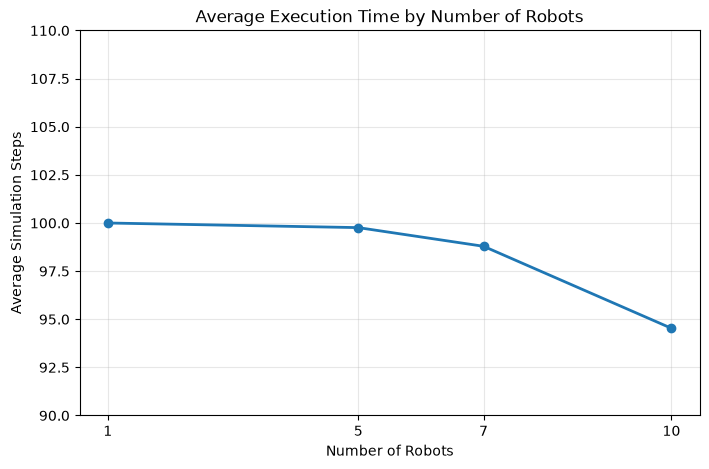

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    results["Number of Robots"],
    results["Average Execution Time"],
    marker="o",
    linewidth=2
)

plt.title("Average Execution Time by Number of Robots")
plt.xlabel("Number of Robots")
plt.ylabel("Average Simulation Steps")
plt.xticks(results["Number of Robots"])
plt.ylim(90, 110)
plt.grid(True, alpha=0.3)

plt.show()

## Average Total Movements

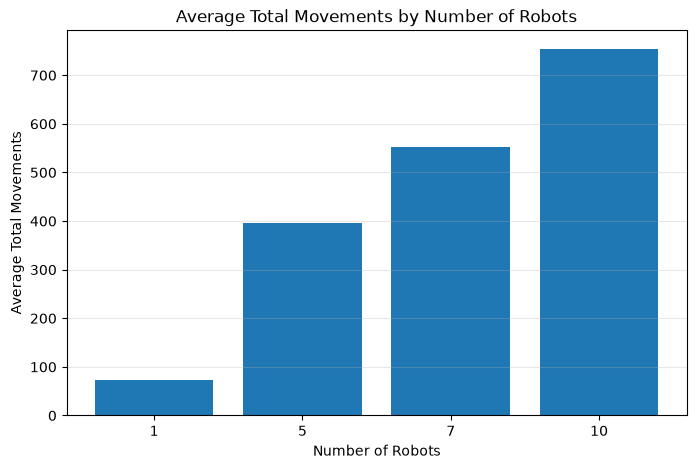

In [10]:

plt.figure(figsize=(8, 5))

plt.bar(
    results["Number of Robots"].astype(str),
    results["Average Total Movements"]
)

plt.title("Average Total Movements by Number of Robots")
plt.xlabel("Number of Robots")
plt.ylabel("Average Total Movements")
plt.grid(axis="y", alpha=0.3)

plt.show()

## Average Percentage of Clean Cells

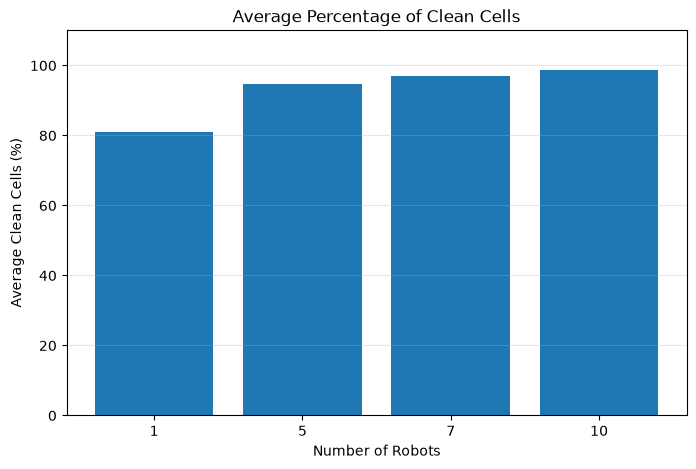

In [12]:

plt.figure(figsize=(8, 5))

plt.bar(
    results["Number of Robots"].astype(str),
    results["Average Clean Cells (%)"]
)

plt.title("Average Percentage of Clean Cells")
plt.xlabel("Number of Robots")
plt.ylabel("Average Clean Cells (%)")
plt.ylim(0, 110)
plt.grid(axis="y", alpha=0.3)

plt.show()

## Success Rate

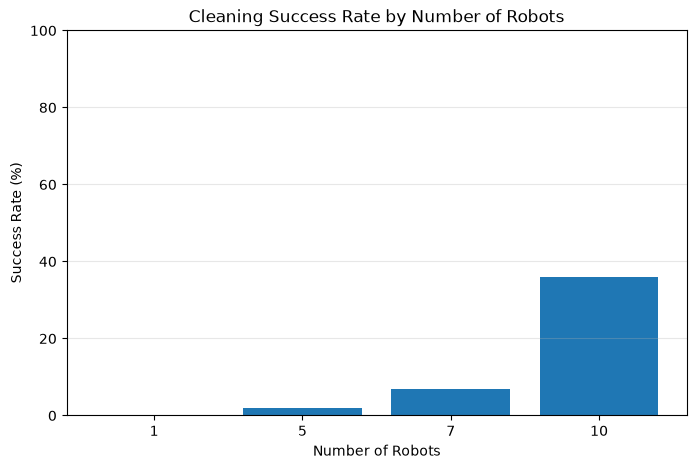

In [13]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Number of Robots"].astype(str),
    results["Success Rate (%)"]
)

plt.title("Cleaning Success Rate by Number of Robots")
plt.xlabel("Number of Robots")
plt.ylabel("Success Rate (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.show()

## 6. Results Discussion

After comparing the results of the four experiments, we observed that increasing the number of robots improved the cleaning process, although it also increased the total number of movements.

First, looking at the execution time, we can see that using one robot resulted in an average of 100 steps, while using ten robots reduced this value to 94.53 steps. This shows that adding more robots can help finish the cleaning process sooner. However, the difference was relatively small because many simulations still reached the maximum limit of 100 steps without cleaning the entire room.

Next, we analyzed the total movements. With one robot, the average was 72.16 movements, while ten robots made an average of 754.35 movements. This increase makes sense because more robots are moving around the room during the simulation. Although using more robots improved the cleaning results, it also required more movements overall.

We also noticed an improvement in the percentage of clean cells. With one robot, the average was 80.95%, while ten robots reached 98.73%. This suggests that having more robots increases the chances of reaching dirty cells and cleaning a larger part of the room.

However, the success rate showed an important difference. With one robot, none of the 100 simulations managed to clean the entire room. With five robots, only 2% succeeded, while seven robots reached 7% and ten robots reached 36%. Even though ten robots cleaned almost the entire room on average, they did not always manage to clean every cell.

We believe this happens because the robots move randomly and do not remember which cells they have already visited. As a result, they may move through the same areas several times while leaving other cells unvisited.

Overall, the results show that adding more robots improves the percentage of clean cells and increases the probability of completing the task. However, it also increases the total number of movements, and the improvement in execution time is limited by the random movement strategy.


## 7. Conclusions

Through this activity, we were able to analyze how the number of cleaning robots affects the time needed to clean a room and the total number of movements they make.

After running several simulations with 1, 5, 7, and 10 robots, we observed that increasing the number of agents generally improved the cleaning results. With one robot, the average percentage of clean cells was 80.95%, while ten robots reached 98.73%. This shows that having more robots helps cover a larger part of the room.

However, we also found that using more robots increases the total number of movements. While one robot made an average of 72.16 movements, ten robots made 754.35 movements. This means that improving the cleaning results also required more movement overall.

Regarding execution time, we noticed that the average decreased from 100 steps with one robot to 94.53 steps with ten robots. However, this improvement was limited because many simulations reached the maximum number of steps without completely cleaning the room.

One of the most interesting findings was that even with ten robots, only 36% of the simulations successfully cleaned the entire room. We believe this is mainly related to the random movement strategy, since the robots can visit the same cells multiple times instead of exploring areas that have not been cleaned.

Based on these results, we concluded that adding more robots improves cleaning coverage and increases the probability of completing the task, but it does not necessarily make the process more efficient in terms of total movements.

As a possible improvement, we could implement a strategy where robots remember the cells they have already visited or communicate with each other to avoid repeating the same paths. This could help them cover the room more efficiently and reduce unnecessary movements.

Overall, this project helped us understand how the behavior and number of agents can affect the performance of a multi-agent system, and how simulations can be used to compare different configurations and evaluate their results.